# Labjournaal brandblusproef

## Algemeen
In een jupyter labjournaal maak je gebruik van markdown. Voor veel gebruikte notaties, [check de documentatie](https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html).

**Namen & studentnummer**

-  Youri Israel 6815049
- Pim van der Heijden 684817

Het meten aan tehermodynamische cylci is lastig in een practicumsetting. In dit experiment doen we wel een poging om karakteristieken van zo'n cyclus te bekijken. We maken daarbij gebruik van een drukvat (brandblusser) waarbij we een druksensor en temperatuursensor tot onze beschikking hebben.

Deze proef bestaat uit drie delen: 
1. IJken van de te gebruiken druksensor
2. Bepalen van het doodvolume van een tube
3. Het vullen en leeglopen van een brandblusser

## Introductie
In de experimentele natuurkunde was het lang geleden gelukt om de krachten tussen ladingen te bestuderen zonder dat bekend was hoe groot die ladingen nu precies waren. Men laadde een metalen bol op en hield deze tegen een andere metalen bol van hetzelfde materiaal. Men redeneerde dat de ladingen op de bollen gelijk waren omdat ze van hetzelfde materiaal waren. Vervolgens plaatste men de bollen in een vacuüm en mat men de krachten tussen de bollen met een zeer gevoelige balans. Op deze manier kon men de krachten tussen de ladingen bestuderen zonder de absolute waarde van de ladingen te kennen. Dit trucje kon herhaald worden met andere bollen waarna een kwantitatieve beschrijving van de krachten tussen ladingen mogelijk werd.

Een soortgelijke meettechniek gaan we gebruiken om een druksensor te ijken. Van de sensor zijn wel wat dingen bekend, maar omdat de spanning van de Arduino niet overeenkomstig is met de gewenste spanning, zouden we deze moeten ijken. We weten dat de sensor lineair is, dus als we twee punten weten, kunnen we de rest van de curve bepalen. Nog beter zou het zijn om drie punten te nemen en zo ook het lineaire karakter van de sensor te bevestigen.

## Theorie
Een injectiespuit met een maximaal volume van 50 mL is gevuld met lucht. De spuit kan aan een kant afgesloten worden met een tube die verbonden is met een druksensor die de gasdruk meet. Door de zuiger van de spuit in te drukken, wordt het volume verkleind en de druk verhoogd. Wanneer we de druk langzaam in drukken verwachten we dat de druk in de spuit volgens de wet van Boyle toeneemt:

$$
    P_1 V_1 = P_2 V_2 
$$ (eq:Boyle)

Omdat de gemeten spanning van de druksensor lineair afhankelijk is van de druk, kan de druk uitgedrukt worden als:

$$
    P = a U + b
$$ (eq:lineair)

## Materialen
In dit experiment maken we gebruik van een druksensor en een temperatuursensor welke verbonden zijn met een Arduino. Een Arduino is een microcontroller: een stukje elektronica dat geprogrammeerd kan worden. Binnen het eerstejaars vak DEF leer je daar alles over. Voor nu is het belangrijk dat je begrijpt dat de Arduino de sensoren uitleest en de data wegschrijft naar een microSD. Deze kunnen we uitlezen met behulp van Python. Daarvoor hebben het programma `read_minisd_write_csv.py` geschreven. Deze maakt verbinding met de Arduino, vraagt naar de naam waaronder je de data op wilt slaan, leest de SD kaart uit en slaat deze op je computer op.

Run `pixi run python read_minisd_write_csv.py` om de data op je computer op te slaan - of: `pixi run read_data`.


```{tip}
De Arduino zou automatisch herkend moeten worden m.b.v. het script dat we hebben gemaakt. Gebeurt dit niet, vraag de TA. **NB:** de code is niet getest voor de MAC. 
```

### Werking Arduino
Wanneer de Arduino uitstaat, houd de **A**-knop drie seconden ingedrukt en deze zal opstarten. De Arduino is zo geprogrammeerd dat deze niets doet tenzij knop **B** of **C** ingedrukt wordt. Druk je knop **B** in, dan wordt de data op de SD kaart gewist. Druk je knop **C** in, dan start na 10 seconde de metingen.

Is je meting klaar, druk dan 3 seconde knop **C** in om de Arduino uit te zetten.

```{tip}
Het is handig om voordat je je eigen metingen gaat beginnen de SD kaart te wissen.
```

## Uitvoering Deel 1 & 2

### IJken van de druksensor
Stel de injectiespuit in op 40 mL en sluit de spuit aan op de druksensor door middel van een zo klein mogelijke tube. 

Start de Arduino op, en start de meetreeks door op knop **C** te drukken. Let op! De Arduino begint pas na 10 seconde te meten.

'Meet' de spanning van de druksensor bij atmosferische druk ($U_1$). Druk vervolgens de zuiger langzaam in tot 20 mL en 'meet' opnieuw de spanning van de druksensor, noteer deze waarde als $U_2$. Herhaal dit bij een volume van 10 mL. 

Stop de meting, lees de data uit en ga door met de volgende vragen.

```{exercise}
Beantwoord de volgende vragen.
```

1. Leg uit waarom een zo klein mogelijke tube gebruikt moet worden.
2. Welke waarde hoort bij de gasdruk bij 40 mL? Zoek deze waarde op.
3. Welke waarden horen bij de gasdruk bij 20 en 10 mL? 
4. Gebruik de drie punten om de waarden van $a$ en $b$ in {numref}`vergelijking {number} <eq:lineair>` te bepalen en controleer of de sensor inderdaad lineair is door de waarden te plotten.

1. Dan is de druk makkelijker te reguleren
2. Dat is gelijk aan 1 atm, op dit moment in delft 102012 Pa
3. Bij 20 ml in principe 2 atm dus 204024 en bij 40 ml in principe 4 atm dus 408048
4. Zie code hieronder, is inderdaad linear

a = 799 Pa/ADC, b = -110431 Pa


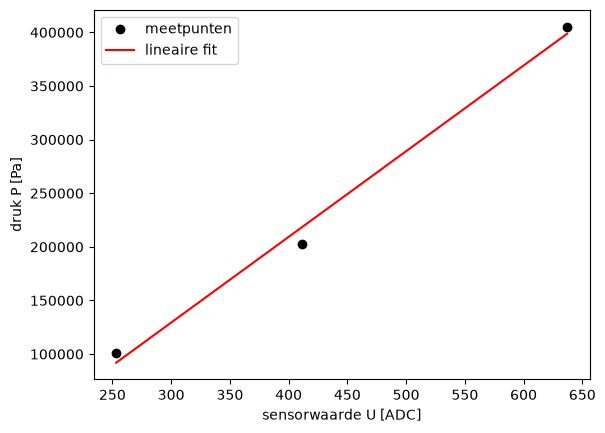

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = np.genfromtxt('Thermo_Groot_14_34.csv', delimiter=',', skip_header=1, invalid_raise=False)
t = data[:, 0] / 1000      # tijd [s]
U = data[:, 1]             # sensorwaarde [ADC]

# gemiddelde sensorwaarde op de stabiele stukken bij 40, 20 en 10 mL
V = np.array([40, 20, 10])
U_gem = np.array([np.mean(U[(t > 37) & (t < 41)]),
                  np.mean(U[(t > 46) & (t < 48)]),
                  np.mean(U[(t > 53) & (t < 57)])])

# druk volgens Boyle
P_atm = 101325             # Pa
P = P_atm * 40 / V

# lineaire fit P = a U + b
def lineair(U, a, b):
    return a * U + b

(a, b), cov = curve_fit(lineair, U_gem, P)
print(f"a = {a:.0f} Pa/ADC, b = {b:.0f} Pa")

plt.plot(U_gem, P, 'ko', label='meetpunten')
plt.plot(U_gem, lineair(U_gem, a, b), 'r-', label='lineaire fit')
plt.xlabel('sensorwaarde U [ADC]')
plt.ylabel('druk P [Pa]')
plt.legend()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#Jouw code

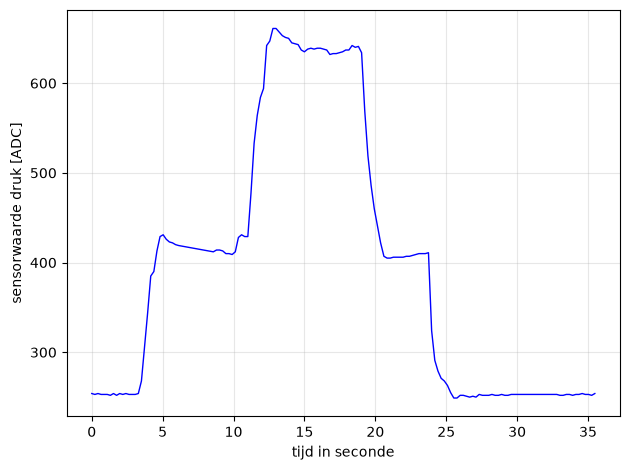

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Data inlezen: tijd [ms], ruwe waarde druksensor [ADC], temperatuur [°C]
# invalid_raise=False slaat regels met een verkeerd aantal kolommen over
data = np.genfromtxt('Thermo_Groot_14_34.csv', delimiter=',', skip_header=1, invalid_raise=False)
t_ms, U, T = data[:, 0], data[:, 1], data[:, 2]

plt.plot(t, U, 'b-', lw=1)
plt.ylabel('sensorwaarde druk [ADC]')
plt.grid(alpha=0.3)
plt.xlabel("tijd in seconde")

fig.suptitle('Meting TG_14_26')
plt.tight_layout()
plt.show()

### Bepalen van 'dood' volume
Vervang daarbij de kleine tube voor een langere en bepaal het onbekende volume van de tube met een volgende meetserie waarbij je de druk en het volume bepaalt. Zorg ervoor dat ook drukken onder de 1 atm gemeten worden. 

```{tip}
Maak gebruik van een systematische fout in het volume om het volume van de tube te vinden.
```

dood volume V0 = 6.0 ± 0.6 mL
ijking: P = 498 * U + (-23912) Pa


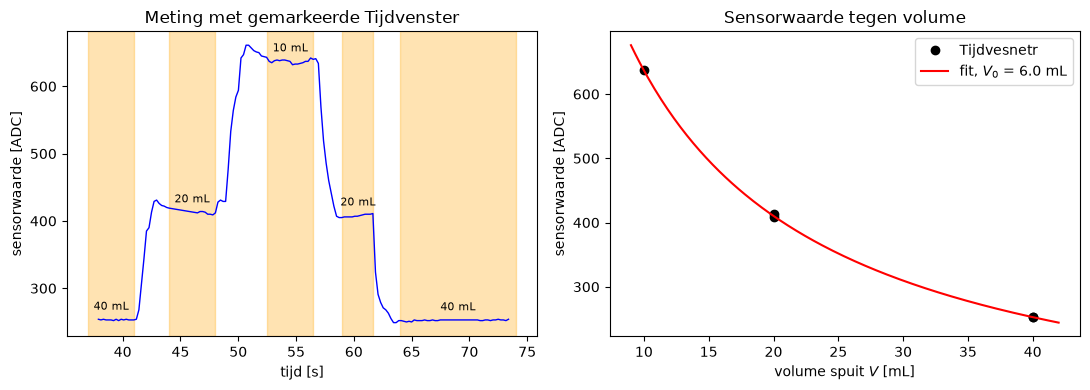

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Data inlezen: tijd [ms], ruwe waarde druksensor [ADC], temperatuur [°C]
data = np.genfromtxt('Thermo_Groot_14_34.csv', delimiter=',', skip_header=1, invalid_raise=False)
t = data[:, 0] / 1000          # tijd in s
U = data[:, 1]                 # sensorwaarde [ADC]

# Tijdvenster: tijdvensters waarin het volume vast stond en de druk tot rust was gekomen
# (net na het indrukken is de druk even hoger doordat het gas opwarmt)

Tijdvenster = [   # (volume spuit [mL], begin [s], eind [s])
    (40, 37.0, 41.0),
    (20, 44.0, 48.0),
    (10, 52.5, 56.5),
    (20, 59, 61.7),
    (40, 64.0, 74.0),]

V   = np.array([p[0] for p in Tijdvenster], dtype=float)

U_p = np.array([np.mean(U[(t >= b) & (t <= e)]) for _, b, e in Tijdvenster])

# Model: Boyle met dood volume, P (V + V0) = constant, en een lineaire sensor P = a U + b
# Samen geeft dat U = A / (V + V0) + B
def model(V, A, V0, B):
    return A / (V + V0) + B

var, cov = curve_fit(model, V, U_p, p0=[9000, 5, 50])
A, V0, B = var
u_V0 = np.sqrt(cov[1, 1])

# Daaruit volgt ook de ijking van de sensor (bij V = 40 mL is P = P_atm)
P_atm = 102012                         # Pa in delft
a = P_atm * (40 + V0) / A              # Pa per ADC-stap
b = -B * a                             # Pa

print(f"dood volume V0 = {V0:.1f} ± {u_V0:.1f} mL")
print(f"ijking: P = {a:.0f} * U + ({b:.0f}) Pa")

# Grafieken
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(t, U, 'b-', lw=1)
for v, b_, e in Tijdvenster:
    ax1.axvspan(b_, e, color='orange', alpha=0.3)
    ax1.text((b_ + e)/2, np.mean(U[(t >= b_) & (t <= e)]) + 15, f'{v} mL', ha='center', fontsize=8)
ax1.set_xlabel('tijd [s]')
ax1.set_ylabel('sensorwaarde [ADC]')
ax1.set_title('Meting met gemarkeerde Tijdvenster')

VV = np.linspace(9, 42, 200)
ax2.plot(V, U_p, 'ko', label='Tijdvesnetr')
ax2.plot(VV, model(VV, *popt), 'r-', label=f'fit, $V_0$ = {V0:.1f} mL')
ax2.set_xlabel('volume spuit $V$ [mL]')
ax2.set_ylabel('sensorwaarde [ADC]')
ax2.set_title('Sensorwaarde tegen volume')
ax2.legend()

plt.tight_layout()
plt.show()

## Vullen en leeglopen van een drukvat

## Introductie

Wanneer je een gas snel samenperst bij gelijkblijvende volume neemt de temperatuur toe. Wanneer je het gas vervolgens laat ontsnappen, neemt de temperatuur af omdat het gas arbeid verricht. 

We gaan eigenschappen van dit proces bestuderen. In dit practicum ga je een $p-t$-diagram van een brandblusser bestuderen en gebruiken om de specifieke warmte verhouding $\gamma$ te bepalen voor lucht.


```{warning}
De buis met de sensoren is kwetsbaar. Leg de brandblusser horizontaal op de tafel en steek de buis met sensoren met de usb kabel zijde er voorzichtig in.
```

## Experiment (60 min)
In dit experiment vullen we een brandblusser met lucht ($P_1, T_1=T_{atm}$). Dit proces is eigenlijk irrelevant voor deze proef, maar we kunnen uit de data halen dat de temperatuur stijgt wanneer de blusser gevuld wordt met lucht. Idealiter laten we het gas in de fles tot rust komen waardoor de temperatuur na het vullen iets kan dalen.

We laten de lucht snel ontsnappen totdat de druk gelijk is aan de atmosferische druk ($P_2=P_{atm}, T_2$). Dit gebeurt in zo'n korte tijd dat we aannemen dat dit een adiabatisch proces is. Doordat het gas arbeid verricht zal het gas afkoelen. Wanneer we dan, kort na het ontsnappen van de lucht, de kraan weer dicht doen, zal de druk in de fles weer toenemen doordat de temperatuur van het gas weer toeneemt ($P_3,T_3=T_{atm}$). 

In het eerste deel van het proces geldt: 

$$
  T_1^\gamma P_1^{1-\gamma} = T_2^\gamma P_2^{1-\gamma}
$$

met $\gamma$ de specifieke warmte verhouding: $\gamma=\frac{C_p}{C_V}$.


```{exercise}
Ga bovenstaande formule na.
```


Bij een adiabatisch proces geldt $PV^\gamma = \text{constant}$. Voor een ideaal gas is
$V = \frac{nRT}{P}$. Invullen geeft

$$
P\left(\frac{nRT}{P}\right)^\gamma = (nR)^\gamma \, P^{1-\gamma} T^\gamma = \text{constant}.
$$

Omdat $n$ en $R$ constant zijn, is ook $T^\gamma P^{1-\gamma}$ constant, dus

$$
T_1^\gamma P_1^{1-\gamma} = T_2^\gamma P_2^{1-\gamma}.
$$


Het tweede deel van het proces, het toenemen van de druk door verhogen van de temperatuur kan beschreven worden met de wet van Gay-Lussac:

$$ 
  \frac{P_2}{T_2} = \frac{P_3}{T_3}
$$

Onder de aanname dat $T_1 = T_3 = T_{atm}$ volgt hieruit:

$$
 \gamma=\frac{\ln{P_1}-\ln{P_{atm}}}{\ln{P_1}-\ln{P_3}}
$$

```{exercise}
1. Zet de druksensor voorzichtig in het brandblusapparaat. Vul de fles met lucht met behulp van de fietspomp (1 bar overdruk is voldoende). 
2. Wacht een tijdje. Waarom?
3. Knijp in de hendel zodat de lucht ontsnapt. Zodra het lucht niet meer ontsnapt, laat de hendel los zodat er geen uitwisseling van lucht meer is.
4. Wacht een korte tijd en haal dan je Arduino en de sd-kaart uit de blusser.
5. Lees de waarden uit in je eigen python script en bepaalde waarde van $\gamma$. Vergelijk deze met de literatuurwaarde ($\gamma = 1.45$)
6. Herhaal de gehele proef een aantal keer en bij verschillende drukken om ook de experimenteel verkregen waarden te vergelijken.
```

```{code-cell} ipython3
2. Zodat de temperatuur daalt tot de kamer temperatuur
```

gamma = 1.217


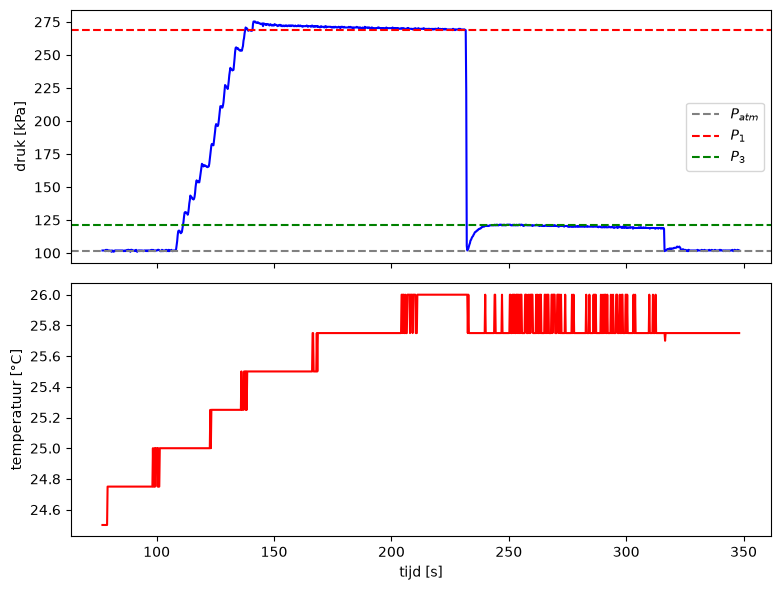

In [34]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt('bb_15_06_2bar.csv', delimiter=',', skip_header=1, invalid_raise=False)
t = data[:, 0] / 1000      # tijd [s]
U = data[:, 1]             # sensorwaarde [ADC]
T = data[:, 2]             # temperatuur [°C]

# ijking van de druksensor (uit de meting met de spuit)
P = a * U + b

# drie drukken: gemiddelde over een stabiel stuk
s_atm = t < 105                      # voor het oppompen
s_1   = (t > 225) & (t < 231.6)      # vlak voor het leeglaten
s_3   = (t > 240) & (t < 256)        # plateau na het sluiten

P_atm, P1, P3 = np.mean(P[s_atm]), np.mean(P[s_1]), np.mean(P[s_3])


# gamma en foutvoortplanting
A = np.log(P1/P_atm)
B = np.log(P1/P3)
gamma = A / B


print(f"gamma = {gamma:.3f}")

# druk en temperatuur tegen de tijd
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(t, P/1e3, 'b-')
ax1.axhline(P_atm/1e3, color='gray', ls='--', label='$P_{atm}$')
ax1.axhline(P1/1e3, color='r', ls='--', label='$P_1$')
ax1.axhline(P3/1e3, color='g', ls='--', label='$P_3$')
ax1.set_ylabel('druk [kPa]')
ax1.legend()

ax2.plot(t, T, 'r-')
ax2.set_xlabel('tijd [s]')
ax2.set_ylabel('temperatuur [°C]')
plt.tight_layout()
plt.show()

gamma = 1.221


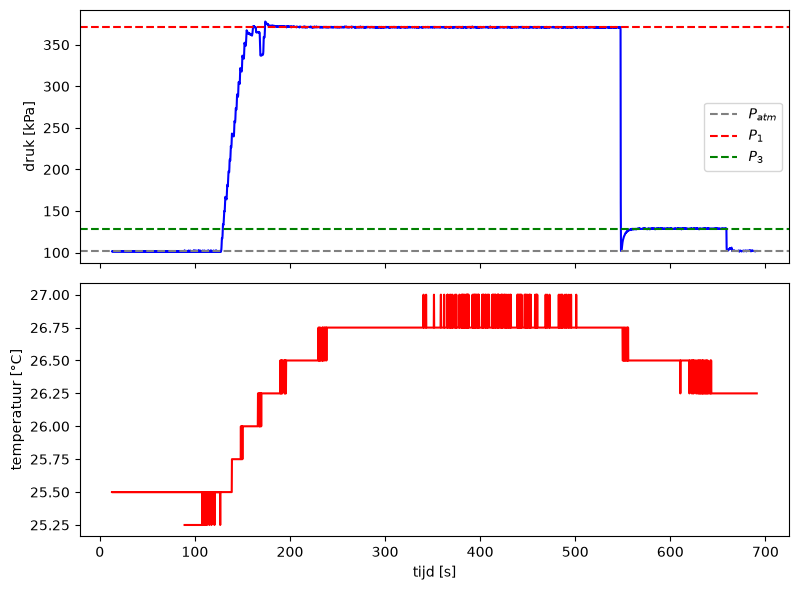

In [33]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt('bb_15_25_3bar.csv', delimiter=',', skip_header=1, invalid_raise=False)
t = data[:, 0] / 1000      # tijd [s]
U = data[:, 1]             # sensorwaarde [ADC]
T = data[:, 2]             # temperatuur [°C]

# ijking van de druksensor (uit de meting met de spuit)
P = a * U + b

# drie drukken: gemiddelde over een stabiel stuk
s_atm = t < 127                      # voor het oppompen
s_1   = (t > 400) & (t < 547.5)      # vlak voor het leeglaten
s_3   = (t > 570) & (t < 659)        # plateau na het sluiten

P_atm, P1, P3 = np.mean(P[s_atm]), np.mean(P[s_1]), np.mean(P[s_3])


# gamma en foutvoortplanting
A = np.log(P1/P_atm)
B = np.log(P1/P3)
gamma = A / B


print(f"gamma = {gamma:.3f}")

# druk en temperatuur tegen de tijd
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(t, P/1e3, 'b-')
ax1.axhline(P_atm/1e3, color='gray', ls='--', label='$P_{atm}$')
ax1.axhline(P1/1e3, color='r', ls='--', label='$P_1$')
ax1.axhline(P3/1e3, color='g', ls='--', label='$P_3$')
ax1.set_ylabel('druk [kPa]')
ax1.legend()

ax2.plot(t, T, 'r-')
ax2.set_xlabel('tijd [s]')
ax2.set_ylabel('temperatuur [°C]')
plt.tight_layout()
plt.show()

gamma = 1.177


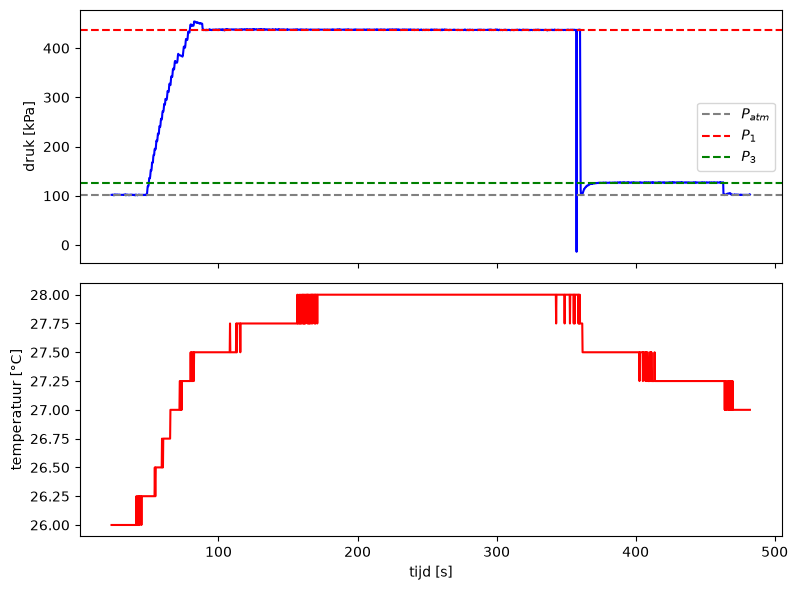

In [31]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt('bb_15_40_4bar.csv', delimiter=',', skip_header=1, invalid_raise=False)
t = data[:, 0] / 1000      # tijd [s]
U = data[:, 1]             # sensorwaarde [ADC]
T = data[:, 2]             # temperatuur [°C]

# ijking van de druksensor (uit de meting met de spuit)
P = a * U + b

# drie drukken: gemiddelde over een stabiel stuk
s_atm = t < 48                       # voor het oppompen
s_1   = (t > 150) & (t < 360)        # vlak voor het leeglaten
s_3   = (t > 390) & (t < 463)        # plateau na het sluiten

P_atm, P1, P3 = np.mean(P[s_atm]), np.mean(P[s_1]), np.mean(P[s_3])


# gamma en foutvoortplanting
L1 = np.log(P1/P_atm)
L2 = np.log(P1/P3)
gamma = L1 / L2

print(f"gamma = {gamma:.3f}")

# druk en temperatuur tegen de tijd
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(t, P/1e3, 'b-')
ax1.axhline(P_atm/1e3, color='gray', ls='--', label='$P_{atm}$')
ax1.axhline(P1/1e3, color='r', ls='--', label='$P_1$')
ax1.axhline(P3/1e3, color='g', ls='--', label='$P_3$')
ax1.set_ylabel('druk [kPa]')
ax1.legend()

ax2.plot(t, T, 'r-')
ax2.set_xlabel('tijd [s]')
ax2.set_ylabel('temperatuur [°C]')
plt.tight_layout()
plt.show()

Onze gevonden waarden is ongeveer 1,2 dit is onder de literatuur waarde. Dat komt omdat de temperattur constanter bleef dan wij verwacht hadden in de brandblusser waardoor de stelling: $T_1 = T_3 = T_{atm}$ niet geldig is. Wel is ons antwoord in de goede oorde van grootheid dus waarschijnlijk zit er een systematische fout van de temperatuur in onze opstelling en is de rest van het experiment wel geldig